# MLFactor long-only strategy

**Question.** Using monthly factor snapshots, can machine learning build a long-only, monthly-rebalanced stock portfolio that beats an equal-weighted market over the 2010–2018 test period?

**Short answer.**

- **Where the return comes from.** The extra return comes from the *portfolio rule*, not from forecasts. The rule groups stocks by their past return paths, favors names with high upside volatility, holds only positive one-month momentum and leaves the rest in cash.
- **What the models can do.** Four model types, a ten-factor cut, `GridSearchCV` tuning and engineered features never forecast next month's direction meaningfully better than a historical base rate. Added to the rule, the forecasts mostly act as a cash dial.
- **The apparent ML gain.** The one ML result that looked like an improvement was a hidden volatility tilt. Retested against a volatility-neutral target, ML leaves a small stock-picking effect that is not statistically significant. A 50/50 blend of the ML rank with momentum gives the best risk-adjusted test result in this notebook, with caveats.
- **The choice.** The book I would trade is **Top 10 positive-vol**, chosen for growth. It grew faster than equal weight in both training and test, and still does after trading costs. But it carries much more volatility, a lower Sharpe ratio, and an edge that is not statistically significant. Section 9 states that trade-off plainly.

**How to read this notebook.** The model fitting ran in the project's research scripts, and every result was saved with its dates and settings. This notebook reads those saves. It does not refit models or reopen the test file while it renders (`MLFACTOR_READ_ONLY=1`). Where the modeling code matters, cells show the exact estimator, search grid and `GridSearchCV` call that produced the saved numbers.

**Conventions.**
- Annual log growth is 12 × mean(log(1 + r)) of monthly portfolio returns, and CAGR = exp(annual log growth) − 1.
- Volatility and Sharpe use simple monthly returns with a zero risk-free rate.
- Everything is gross of trading costs, and cash earns nothing.
- The label on a snapshot at month *t* is the return earned in month *t + 1*, so decisions only use information available at *t*.

| Assignment item | Where |
|---|---|
| 1. Feature subset of 10 or fewer, and whether it helps | Section 3 |
| 2. Four model types | Section 4 |
| 3. `GridSearchCV` tuning, and whether it helps | Section 5 (5b: on the chosen book, 2010–2018) |
| 4. Equal weight plus a non-ML strategy of my own | Sections 1–2 |
| 5. Risk and reward | Every table, and Section 8 (8b: costs, 8c: significance) |
| 6. Final choice | Section 9 |
| Extensions | Section 6 (feature engineering), Section 7 (does ML beat a volatility tilt?) |

In [1]:
# Setup. Read-only: find the project folder even if the kernel starts inside submission/.
import inspect
import os
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ["MLFACTOR_READ_ONLY"] = "1"          # any accidental model fit raises an error instead of running
here = Path.cwd().resolve()
for candidate in (here, *here.parents):
    if (candidate / "research" / "notebook_views.py").is_file():
        sys.path.insert(0, str(candidate))
        break

from research.notebook_views import PROJECT_ROOT, color_for, prepare_axes, style_table

PERCENT = "{:.2%}"                              # shared display format for return/risk columns

## At a glance: the official test, January 2010 – December 2018

The table puts the main candidates side by side. The first four rows come from the frozen final-book run, fitted on training data and scored once on the test window. The last two come from the Section 7 study, which ranks the whole universe and holds the top 20%. They are listed separately because the two protocols differ.

In [2]:
from research.notebook_views import risk_table, vol_neutral_table

# Official-test rows of the frozen final-book run (the overlay model shown is logistic regression).
frozen = risk_table()
frozen = frozen[frozen["Window"].eq("Official test")]
keep = {"Equal weight": "Equal weight (benchmark)",
        "Top 10 positive-vol": "Top 10 positive-vol (my choice, no ML)",
        "Top 10 + downside to cash": "Top 10 + ML downside-to-cash overlay",
        "Full baskets": "Full baskets (no ML)"}
frozen = frozen[frozen["Book"].isin(keep)].assign(Book=lambda d: d["Book"].map(keep), Protocol="Frozen final books")

# Section 7 rows: the volatility-only rule and the ML + momentum blend, same test months.
part8 = vol_neutral_table("test_2010_2018").rename(columns={"Strategy": "Book"})
part8 = part8[part8["Book"].str.startswith(("Top volatility", "Vol-neutral ML + momentum"))].assign(Protocol="Section 7 study (top 20%)")

columns = ["Book", "Protocol", "Annual log growth", "CAGR", "Volatility", "Sharpe", "Max drawdown"]
glance = pd.concat([frozen[columns], part8[columns]], ignore_index=True)
display(style_table(glance))

Book,Protocol,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight (benchmark),Frozen final books,12.31%,13.10%,15.63%,0.868,-20.64%
"Top 10 positive-vol (my choice, no ML)",Frozen final books,17.91%,19.61%,39.20%,0.591,-21.33%
Top 10 + ML downside-to-cash overlay,Frozen final books,14.53%,15.64%,30.36%,0.590,-16.65%
Full baskets (no ML),Frozen final books,3.93%,4.01%,8.07%,0.528,-12.37%
Top volatility quintile (no ML),Section 7 study (top 20%),16.89%,18.40%,23.31%,0.843,-27.02%
Vol-neutral ML + momentum (w=0.50),Section 7 study (top 20%),14.87%,16.03%,16.04%,1.011,-16.77%


## 1. Data and the equal-weighted benchmark

Each month the data holds roughly 1,000–1,200 stocks. Each stock has 20 fundamental and trading factors stored as cross-sectional percentile ranks from 0.01 to 1, plus the next month's return. Training snapshots cover January 2000 – December 2009 returns (120 months). The official test covers January 2010 – December 2018 returns (108 months).

The **equal-weighted market** holds every stock available at each snapshot with the same weight and rebalances monthly. The cell below recomputes its annualized return directly from the saved monthly portfolio returns. Two formulas must agree:
- compound the gross returns, then annualize;
- take 12 × the mean log return, then exponentiate.

A common mistake is to average stock-level log returns or to annualize the arithmetic mean. Both give a different, wrong number.

In [3]:
from research.notebook_views import equal_weight_benchmark, equal_weight_sentence, source_note

# Saved monthly equal-weight portfolio returns on the official test (one row per month).
monthly = pd.read_csv(PROJECT_ROOT / "part0_data_and_benchmark" / "outputs" / "equal_weight_test_monthly.csv",
                      parse_dates=["return_month"])
r = monthly["simple_return"]                                  # portfolio simple return each month
n_months = len(r)

cagr_compounded = (1 + r).prod() ** (12 / n_months) - 1      # compound, then annualize
annual_log_growth = 12 * np.log1p(r).mean()                  # 12 x mean monthly portfolio log return
cagr_from_logs = np.expm1(annual_log_growth)                 # identical by construction

print(f"{n_months} test months, {monthly['n_assets'].min()}–{monthly['n_assets'].max()} stocks per month")
print(f"CAGR, compounded gross returns : {cagr_compounded:.4%}")
print(f"CAGR, exp(annual log growth)-1 : {cagr_from_logs:.4%}")
print(f"Annual log growth              : {annual_log_growth:.4%}")
assert np.isclose(cagr_compounded, cagr_from_logs)

# The same benchmark from the project's saved summary, with risk columns and the training window.
print()
print(source_note("benchmark"))
display(style_table(equal_weight_benchmark()))
print(equal_weight_sentence())

108 test months, 1109–1194 stocks per month
CAGR, compounded gross returns : 13.0964%
CAGR, exp(annual log growth)-1 : 13.0964%
Annual log growth              : 12.3070%

Independent equal-weight files. Training is January 2000–December 2009, 120 months. The official test is January 2010–December 2018, 108 months. Combined compounds those monthly simple returns, January 2000–December 2018. Annual log growth is 12 * mean(log(1 + r)). CAGR is exp(that) - 1.


Period,Months,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Training,120,13.54%,14.50%,19.92%,0.783,-49.51%
Official test,108,12.31%,13.10%,15.63%,0.868,-20.64%
Combined,228,12.95%,13.83%,17.98%,0.814,-49.51%


The graded equal-weight figure is the official-test CAGR, 13.096%, over 108 months. Annual log growth on that same path is 12.307%. The combined path, January 2000 through December 2018, has annual log growth 12.955% and CAGR 13.831%.


## 2. Two non-ML strategies

Equal weight is the benchmark. The second non-ML strategy is my own, and it comes in two versions. Both are long-only and gross of costs, and cash earns nothing.

**How the momentum books are built, each month:**
1. Take stocks with a complete 12-month return history and split them into **five K-means groups** using those past return paths. The groups are refit every month.
2. **Top 10 positive-vol** keeps, in each group, at most the ten names with the highest *positive volatility*. That is the root-mean-square of the up months, with down months counted as zero. **Full baskets** keeps every name.
3. A group whose own last-month return was not positive goes to **cash**. Inside a group that was up, only members that were up get weight, in proportion to that one-month return.

The groups need twelve months of history, so the training window for these books is January 2005 – December 2009.

Newest final-book save final_20261110T025420_6d3405bd: 2010-01-31 through 2018-12-31, frozen_at_origin at 2009-12-31. Training window 2005-01-31 through 2009-12-31.


Window,Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Average cash
Training window · Jan 2005–Dec 2009,Equal weight,7.34%,7.62%,23.19%,0.433,-49.51%,0.00%
Training window · Jan 2005–Dec 2009,Top 10 positive-vol,19.26%,21.24%,33.13%,0.719,-21.36%,50.50%
Training window · Jan 2005–Dec 2009,Full baskets,9.16%,9.59%,15.48%,0.663,-15.51%,57.96%
Official test · Jan 2010–Dec 2018,Equal weight,12.31%,13.10%,15.63%,0.868,-20.64%,0.00%
Official test · Jan 2010–Dec 2018,Top 10 positive-vol,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test · Jan 2010–Dec 2018,Full baskets,3.93%,4.01%,8.07%,0.528,-12.37%,54.18%
Combined path · Jan 2005–Dec 2018,Equal weight,10.53%,11.11%,18.62%,0.661,-49.51%,0.00%
Combined path · Jan 2005–Dec 2018,Top 10 positive-vol,18.39%,20.19%,37.05%,0.632,-21.36%,51.18%
Combined path · Jan 2005–Dec 2018,Full baskets,5.80%,5.97%,11.27%,0.568,-15.51%,55.53%


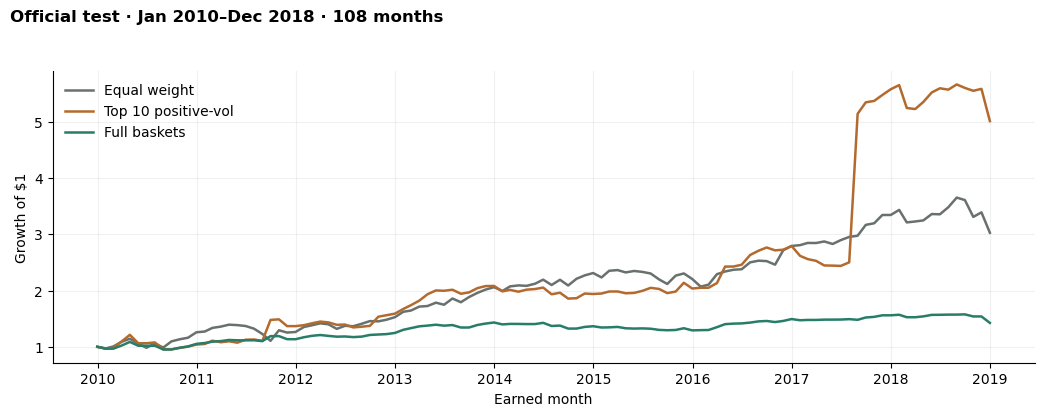

In [4]:
from research.notebook_views import non_ml_figure, non_ml_windows_table

# Newest saved final-book run: training window, official test, and the two compounded together.
print(source_note("final"))
display(style_table(non_ml_windows_table()))
display(non_ml_figure("test"))
plt.close("all")

**Reading it.** Top 10 positive-vol grows faster than equal weight in both windows, so the result is not a test-period accident. It does that with roughly half the capital in cash and about two and a half times the volatility of equal weight on the test. Full baskets is the low-risk version: small drawdowns, but test growth well below the market.

## 3. Feature selection: choosing 10 or fewer factors

**The analysis behind the choice.** Many of the 20 factors measure the same thing. Most of the debt measures move together, the three share-turnover windows are almost the same series, and the cash-flow ratios cluster. The correlation map below, from the training data, shows those blocks. With redundant inputs, a model can drop half the list and lose almost nothing. Naive Bayes, which assumes its inputs are independent, is the model most exposed to that redundancy.

**The methods.** I compared three ways to keep 10 factors against using all 20:
- ANOVA F-score top 10;
- correlation-pruned top 10, which skips any factor with |r| ≥ 0.90 to an already chosen one;
- random-forest importance top 10.

Each selector is a step *inside* the model pipeline, so it is refit on training data in every fold and never sees validation or test labels. The frozen official-test models use the ANOVA top 10.

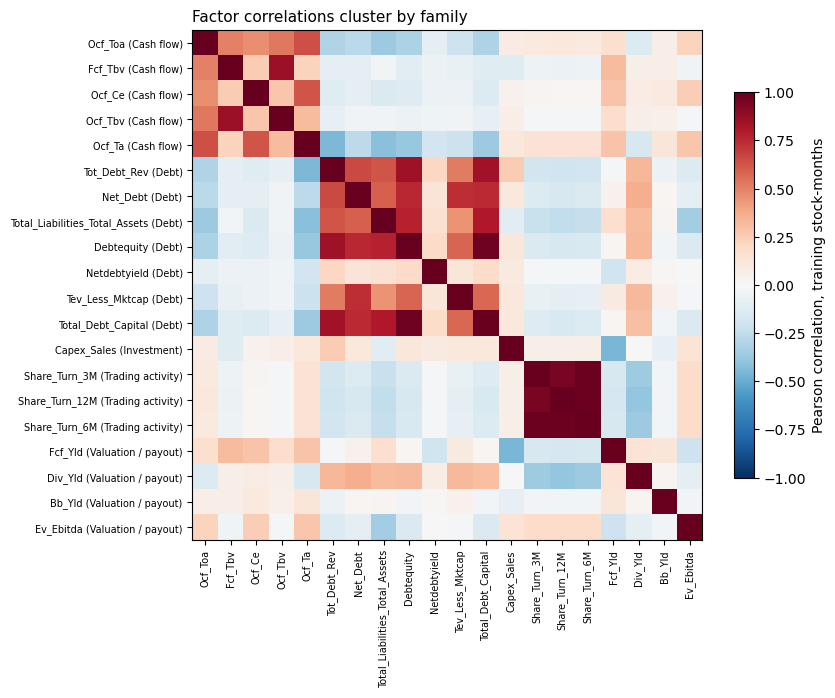

12 of 190 factor pairs have |correlation| >= 0.7


In [5]:
# Training-data factor correlations (saved by the data-exploration step), grouped by economic family.
corr = pd.read_csv(PROJECT_ROOT / "part0_data_and_benchmark" / "outputs" / "training_feature_correlations.csv", index_col=0)
families = pd.read_csv(PROJECT_ROOT / "part0_data_and_benchmark" / "outputs" / "feature_dictionary.csv").set_index("feature")["family"]
order = families.sort_values(kind="stable").index                # debt, cash flow, turnover ... side by side
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order)), [f"{name} ({families[name]})" for name in order], fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.75, label="Pearson correlation, training stock-months")
ax.set_title("Factor correlations cluster by family", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

# How many pairs are strongly redundant?
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"{(upper.abs() >= 0.7).sum()} of {len(upper)} factor pairs have |correlation| >= 0.7")

In [6]:
from research.features import FeatureSpec
from research.models import default_model_registry

# The exact pipeline used by the frozen official-test models: ANOVA selection of 10 factors,
# fitted on training rows only, then scaling, then the classifier. Displayed, not fitted.
anova_10 = FeatureSpec(selection="anova", k=10)
display(default_model_registry()["logistic"].pipeline(anova_10))

Pipeline(steps=[('feature_selection', TrainingFeatureSelector()),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=0))])

In [7]:
from research.notebook_views import feature_cut_table, feature_name_note

# Training-window CAGR of each overlay book when its model sees all 20 factors vs. each 10-factor cut.
print(source_note("features"))
cuts = feature_cut_table()
display(cuts.style.format({column: PERCENT for column in cuts.columns if column != "Book"}, na_rep="—").hide(axis="index"))
print(feature_name_note())

Newest feature-score save features_20261110T022741_e6f5661f: 2005-01-31 through 2009-12-31. This window is the training years.


Book,All 20 original factors,ANOVA top 10,Correlation-pruned up to 10 (|r| < 0.90),Random forest top 10,Largest gap vs all 20
Top 10 + downside to cash,19.41%,19.42%,19.40%,19.47%,0.06%
Top 10 + upside tilt,24.98%,24.78%,24.86%,24.78%,-0.20%
Baskets + downside to cash,7.92%,7.91%,7.91%,7.93%,0.01%
Baskets + upside tilt,10.01%,9.98%,10.00%,9.98%,-0.04%


Inside the frozen fit, 10 names were chosen for Logistic regression, and loss and upside use the same list: Tot_Debt_Rev, Net_Debt, Share_Turn_3M, Debtequity, Ocf_Ce, Div_Yld, Share_Turn_12M, Tev_Less_Mktcap, Total_Debt_Capital, Share_Turn_6M. On the training years recorded by the newest feature-score study (2005-01-31 through 2009-12-31, 60 months), not the official test, the largest absolute CAGR gap versus all 20 for Logistic regression is 0.20 percentage points below all 20, on Top 10 + upside tilt under Random forest top 10; the cut does not meaningfully change the book, and it satisfies a ten-or-fewer feature limit.


**Does restricting to 10 factors improve the strategy?** Not measurably. Every 10-factor cut moves the training-window CAGR by at most about 0.2 percentage points versus all 20, in either direction. That is the expected result once we see in Section 4 that the forecasts barely move the books. I keep ANOVA top 10 because it is the simplest cut, it meets the limit, and it costs nothing in performance.

## 4. Four model types

**The models.**
- Logistic regression (linear in the log-odds; tunable `C`).
- Gaussian naive Bayes (assumes independent inputs within each class).
- Random forest (averaged shallow trees; tunable depth and leaf size).
- Histogram gradient boosting (sequential small trees; tunable learning rate and tree size).

Each predicts, for every stock, the probability that next month's return is negative ("down") or positive ("up").

**How the forecasts enter a portfolio.** The models do not pick new stocks. They adjust the momentum books from Section 2:
- **Downside to cash** multiplies each held weight by (1 − 0.5 × P(down)) and moves the reduction to cash.
- **Upside tilt** multiplies a weight by 1.5 when P(up) ≥ 0.60, then rescales the stock weights back to the book's original stock budget.

The official-test models were fitted once on all training data with factory settings and frozen.

In [8]:
from research.notebook_views import classifier_growth_table

growth = classifier_growth_table()
print(source_note("final"))

# Compact view: one row per book, one column per model, for the official test and the training window.
for window in ("Official test", "Training window"):
    part = growth[growth["Window"].str.startswith(window)]
    for metric, fmt in (("CAGR", PERCENT), ("Sharpe", "{:.3f}")):
        table = part.pivot_table(index="Book", columns="Model", values=metric, sort=False)
        print(f"\n{window} — {metric}")
        display(table.style.format(fmt, na_rep="—"))

Newest final-book save final_20261110T025420_6d3405bd: 2010-01-31 through 2018-12-31, frozen_at_origin at 2009-12-31. Training window 2005-01-31 through 2009-12-31.

Official test — CAGR


Model,No ML,Logistic regression,Gaussian naive Bayes,Random forest,Histogram gradient boosting
Book,,,,,
Equal weight,13.10%,—,—,—,—
Top 10 positive-vol,19.61%,—,—,—,—
Top 10 + downside to cash,—,15.64%,15.40%,15.64%,15.83%
Top 10 + upside tilt,—,19.61%,19.71%,19.60%,22.35%
Full baskets,4.01%,—,—,—,—
Baskets + downside to cash,—,3.15%,3.10%,3.14%,3.14%
Baskets + upside tilt,—,4.01%,3.84%,4.00%,3.99%



Official test — Sharpe


Model,No ML,Logistic regression,Gaussian naive Bayes,Random forest,Histogram gradient boosting
Book,,,,,
Equal weight,0.868,—,—,—,—
Top 10 positive-vol,0.591,—,—,—,—
Top 10 + downside to cash,—,0.590,0.589,0.588,0.583
Top 10 + upside tilt,—,0.591,0.593,0.590,0.528
Full baskets,0.528,—,—,—,—
Baskets + downside to cash,—,0.527,0.526,0.527,0.527
Baskets + upside tilt,—,0.528,0.521,0.528,0.527



Training window — CAGR


Model,No ML,Logistic regression,Gaussian naive Bayes,Random forest,Histogram gradient boosting
Book,,,,,
Equal weight,7.62%,—,—,—,—
Top 10 positive-vol,21.24%,—,—,—,—
Top 10 + downside to cash,—,16.91%,17.00%,16.50%,16.38%
Top 10 + upside tilt,—,21.34%,20.92%,21.24%,21.35%
Full baskets,9.59%,—,—,—,—
Baskets + downside to cash,—,7.56%,7.56%,7.42%,7.41%
Baskets + upside tilt,—,9.51%,9.16%,9.53%,9.55%



Training window — Sharpe


Model,No ML,Logistic regression,Gaussian naive Bayes,Random forest,Histogram gradient boosting
Book,,,,,
Equal weight,0.433,—,—,—,—
Top 10 positive-vol,0.719,—,—,—,—
Top 10 + downside to cash,—,0.720,0.729,0.720,0.718
Top 10 + upside tilt,—,0.722,0.727,0.719,0.722
Full baskets,0.663,—,—,—,—
Baskets + downside to cash,—,0.663,0.667,0.661,0.661
Baskets + upside tilt,—,0.659,0.655,0.660,0.661


**Reading it.**
- **Downside to cash** lowers return and drawdown together and leaves Sharpe almost unchanged. On the test, Top 10 loses about 4 percentage points of CAGR and its drawdown shrinks. That is what holding more cash does, regardless of which stocks are trimmed.
- **Upside tilt** barely changes the book. The one exception, gradient boosting on the test, adds return only by adding volatility, and its Sharpe falls.
- **The four models behave almost identically.** On the downside overlay they land within about half a percentage point of each other. That is a sign that none of them is ranking stocks better than the others.

### 4b. An extra tuned model: K nearest neighbors on return quintiles

K nearest neighbors (from the textbook) and multinomial logistic regression predict which **quintile** of next month's return a stock will land in. Both are tuned with `GridSearchCV` on labels known by December 2006 and scored on the January 2007 – December 2009 training holdout. The portfolio equal-weights the stocks predicted to land in the top quintile.

In [9]:
from research.notebook_views import grouping_book_table, grouping_class_table, grouping_note, grouping_search_table

print(source_note("grouping"))
display(grouping_search_table().style.format({"Best score": "{:.4f}"}, na_rep="—").hide(axis="index"))
display(grouping_class_table().style.format({"Holdout accuracy": "{:.1%}", "Chance accuracy": "{:.1%}",
                                             "Holdout log loss": "{:.3f}", "Uniform log loss": "{:.3f}"},
                                            na_rep="—").hide(axis="index"))
display(style_table(grouping_book_table()))
print(grouping_note())

Newest grouping study grouping_20261110T044153_b86c80c0: search labels through 2006-12-31, holdout earned returns 2007-01-31 through 2009-12-31. GridSearchCV score neg_log_loss. Training file only.


Model,Searched,Chosen,Fits,Best score
K nearest neighbors,"n_neighbors: 5, 15, 31, 51",n_neighbors=51,13,-1.6239
Logistic regression,"C: 0.1, 1, 10",C=0.1,10,-1.5797


Model,Holdout accuracy,Chance accuracy,Holdout log loss,Uniform log loss
K nearest neighbors,22.6%,20.0%,1.663,1.609
Logistic regression,22.7%,20.0%,1.605,1.609


Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight,2.59%,2.62%,28.48%,0.231,-49.51%
"K nearest neighbors, top category",7.05%,7.30%,34.74%,0.371,-54.26%
"Logistic regression, top category",6.78%,7.01%,33.33%,0.364,-52.06%


K nearest neighbors is one of the model types. GridSearchCV chose n_neighbors=51 for K nearest neighbors and C=0.1 for multinomial logistic regression, using labels through 2006-12-31 and the neg_log_loss score. On the January 2007–December 2009 training holdout, K nearest neighbors accuracy is 22.6% against a chance accuracy of 20.0%. Its holdout log loss is 1.663, and logistic regression holdout log loss is 1.605, against a uniform-guess log loss of 1.609. Its top-category book has annual log growth 7.05% and CAGR 7.30%, against equal weight at 2.59% and 2.62%. This search did not open the official test file. It is not inside the frozen 2010–2018 books, which still use the four factory classifiers. The basket book groups by K-means on return paths; this model groups by the predicted return quintile.


**Reading it.** Accuracy is a little above the 20% you would get by guessing. But K nearest neighbors' log loss is *worse* than a uniform guess, so its confidence is not earned. The top-quintile book beats equal weight on this holdout, with higher volatility and a deeper drawdown.

## 5. Hyperparameter tuning with `GridSearchCV`

**The setup.**
- Each model is searched on a small grid declared before any result was inspected.
- The score is **log loss**, a standard goodness-of-fit metric for probabilities, not portfolio return.
- Cross-validation uses **expanding monthly folds**: each fold trains on earlier months and validates on the next block, and all stocks from one month stay on the same side. Ordinary shuffled K-fold would let the model learn from the future.
- The search uses labels known by December 2006, and the settings it picks are scored on the January 2007 – December 2009 holdout inside the training file.

In [10]:
from research.notebook_views import model_label
from research.tuning import DECLARED_GRIDS, tune_classifier

# The declared grids (the factory default value sits inside each grid).
grids = pd.DataFrame([{"Model": model_label(key),
                       "Grid": "; ".join(f"{name.replace('model__', '')}: {values}" for name, values in grid.items()),
                       "Candidates": int(np.prod([len(values) for values in grid.values()]))}
                      for key, grid in DECLARED_GRIDS.items()])
display(grids.style.hide(axis="index"))

# The exact lines that built and ran the search (printed from the project source, not re-run here).
source = inspect.getsource(tune_classifier)
start = source.index("    splitter = MonthForwardSplit")
end = source.index("    seconds = time.perf_counter()")
print(textwrap.dedent(source[start:end]))

Model,Grid,Candidates
Logistic regression,"C: [0.1, 1.0, 10.0]",3
Gaussian naive Bayes,"var_smoothing: [1e-09, 1e-05]",2
Random forest,"max_depth: [4, 6]; min_samples_leaf: [50, 200]",4
Histogram gradient boosting,"learning_rate: [0.05, 0.1]; max_leaf_nodes: [15, 31]",4


splitter = MonthForwardSplit(work.date, work.label_available_at, n_splits, min_train_months)
folds = splitter.fold_table(work)
pipeline = spec.pipeline(feature_spec)
if fixed_params:
    pipeline.set_params(**fixed_params)
search = GridSearchCV(
    pipeline, search_grid, scoring=scoring, cv=splitter, refit=True,
    n_jobs=1, error_score="raise", return_train_score=False)
started = time.perf_counter()
with threadpool_limits(limits=1):
    search.fit(work[columns], y)



In [11]:
from research.notebook_views import tuning_note, tuning_portfolio_table, tuning_search_table

# What the search chose, and whether the tuned model moved any holdout portfolio.
print(source_note("tuning"))
display(tuning_search_table().style.format({"Best score": "{:.4f}"}, na_rep="—").hide(axis="index"))
books = tuning_portfolio_table()
display(books.style.format({column: PERCENT for column in books.columns if column not in {"Strategy", "Model"}},
                           na_rep="—").hide(axis="index"))
print(tuning_note())

Newest GridSearchCV holdout holdout_20261110T013013_6f2fd4f9: earned returns 2007-01-31 through 2009-12-31. Search score neg_log_loss. Prediction target upside.


Model,Searched,Chosen,Fits,Best score
Logistic regression,"C: 0.1, 1, 10",C: 0.1,10,-0.6817
Gaussian naive Bayes,"var_smoothing: 1e-09, 1e-05",var_smoothing: 1e-05,7,-0.6950
Random forest,"max_depth: 4, 6; min_samples_leaf: 50, 200",max_depth: 4; min_samples_leaf: 200,13,-0.6809
Histogram gradient boosting,"learning_rate: 0.05, 0.1; max_leaf_nodes: 15, 31",learning_rate: 0.05; max_leaf_nodes: 15,13,-0.6818


Strategy,Model,No ML CAGR,Untuned CAGR,Tuned CAGR,Tuned minus untuned
Equal-weight universe,Logistic regression,2.62%,2.30%,2.30%,0.00%
Equal-weight universe,Gaussian naive Bayes,2.62%,2.03%,2.03%,0.00%
Equal-weight universe,Random forest,2.62%,2.47%,2.48%,0.01%
Equal-weight universe,Histogram gradient boosting,2.62%,2.46%,2.46%,0.00%
Training Sortino pool + momentum,Logistic regression,-5.31%,-4.81%,-4.81%,0.00%
Training Sortino pool + momentum,Gaussian naive Bayes,-5.31%,-5.59%,-5.59%,0.00%
Training Sortino pool + momentum,Random forest,-5.31%,-4.96%,-4.76%,0.20%
Training Sortino pool + momentum,Histogram gradient boosting,-5.31%,-4.93%,-4.93%,0.00%
"High volatility, equal weight",Logistic regression,20.41%,20.17%,20.17%,0.01%
"High volatility, equal weight",Gaussian naive Bayes,20.41%,21.17%,21.17%,0.00%


GridSearchCV searched the January 2007–December 2009 training holdout with the neg_log_loss score and the upside prediction target. The largest absolute tuned-minus-untuned CAGR on the equal-weight holdout book is 0.01%, so the portfolio barely moved. These holdout rows are registry rules on the training cut; the official 2010–2018 books in the other cells use factory classifier settings, so this search is not the model inside that test.


**Does tuning to a machine-learning metric improve the strategy?** On this training holdout, no, not in a way that matters. The search does choose different settings, for example more regularization for logistic regression and a shallower forest. But tuned-minus-untuned CAGR is a fraction of a percentage point on every book. The best cross-validated log losses (0.68–0.70) sit right around a coin-flip forecast (0.693). There is very little signal to tune toward, so a better fit score does not become a better portfolio.

### 5b. Did tuning change the chosen book on the official test?

The frozen official-test books above use factory settings. To answer the question for the book I actually chose, a separate study refit every overlay once on all training data with the settings `GridSearchCV` picked, then scored it on 2010–2018. The test was not used to tune anything.

In [12]:
from research.notebook_views import tuned_final_note, tuned_final_table

# Chosen book (Top 10 positive-vol = "K-means top 10" in that study) with factory vs. tuned overlays.
tuned = tuned_final_table()
display(tuned.style.format({"Factory CAGR": PERCENT, "Tuned CAGR": PERCENT, "Tuned − factory CAGR": "{:+.3%}",
                            "Factory Sharpe": "{:.3f}", "Tuned Sharpe": "{:.3f}"}).hide(axis="index"))
print(tuned_final_note())

Model,Overlay,Tuned settings,Factory CAGR,Tuned CAGR,Tuned − factory CAGR,Factory Sharpe,Tuned Sharpe
No ML (the chosen book),—,—,19.61%,19.61%,+0.000%,0.591,0.591
Histogram gradient boosting,Downside to cash,learning_rate=0.05,15.83%,15.83%,+0.000%,0.583,0.583
Histogram gradient boosting,Upside tilt,learning_rate=0.05,22.35%,22.35%,+0.000%,0.528,0.528
Logistic regression,Downside to cash,C=0.1,15.64%,15.64%,-0.003%,0.590,0.590
Logistic regression,Upside tilt,C=0.1,19.61%,19.61%,+0.000%,0.591,0.591
Gaussian naive Bayes,Downside to cash,var_smoothing=1e-05,15.40%,15.40%,+0.000%,0.589,0.589
Gaussian naive Bayes,Upside tilt,var_smoothing=1e-05,19.71%,19.71%,+0.000%,0.593,0.593
Random forest,Downside to cash,"max_depth=4, min_samples_leaf=200",15.64%,15.61%,-0.027%,0.588,0.590
Random forest,Upside tilt,"max_depth=4, min_samples_leaf=200",19.60%,19.60%,+0.000%,0.591,0.591


Study engineering_20261110T171255_825ffa99 refit every overlay once on all 140,739 training rows through 2009-12-31, with the settings GridSearchCV chose on training labels (log loss), and scored 108 test months. On the chosen book, the largest tuned-minus-factory CAGR change is -0.027% (Random forest, downside to cash); the median is 0.000%. Tuning to a better log loss does not change the portfolio, so the factory-setting official books stand in for the tuned ones.


**Reading it.** Tuning picks different settings, but the portfolio is unchanged to within a few hundredths of a percentage point. Where `GridSearchCV` kept the factory value, the rows are identical. The answer to rubric item 3 is the same on the training holdout and on the test: tuning to log loss does not improve this strategy.

## 6. Extension: feature engineering

The factors are redundant (Section 3), so I tried building better inputs instead of just choosing among them. Each recipe has at most 10 inputs:
- **cluster averages** and **cluster principal components** that squeeze each correlated family into one column;
- **IC-weighted blends** that weight factors by their historical rank correlation with next month's return;
- **technical features** from each stock's own past returns, such as moving averages, price versus its moving average, momentum and volatility;
- **economic composites**, such as leverage, cash-flow quality and payout.

Every learned piece (cluster membership, loadings, weights) is fitted inside the chronological training folds. The first table scores the January 2007 – December 2009 holdout without loading the test file.

The second table is an earlier exploratory comparison that did use 2010–2018. It holds the top 20% of stocks by predicted probability, fully invested.

Note: ten constructed inputs can still combine all twenty source factors. ANOVA-10 is the recipe that stays within ten original factors.

In [13]:
from research.notebook_views import engineering_comparison_table, engineering_holdout_table, engineering_note

print(source_note("engineering"))
display(style_table(engineering_holdout_table()))
display(style_table(engineering_comparison_table()).format({"Test AUC": "{:.3f}"}))
print(engineering_note())

Pinned engineering study engineering_20261110T171255_825ffa99. January 2007–December 2009 holdout. The test file is not part of this study's training scope. The 0_7 comparison file is a separate, previously viewed 2010–2018 notebook result.


Recipe,Status,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
anova_10,Fixed,28.33%,32.75%,30.64%,1.063,-16.24%
anova_10,Tuned,28.33%,32.75%,30.64%,1.063,-16.24%
cluster_average,Fixed,27.75%,31.98%,29.93%,1.062,-15.92%
cluster_average,Tuned,27.75%,31.98%,29.93%,1.062,-15.92%
cluster_pca,Fixed,27.73%,31.96%,29.93%,1.062,-15.94%
cluster_pca,Tuned,27.73%,31.96%,29.93%,1.062,-15.94%
economic,Fixed,27.72%,31.95%,29.92%,1.062,-15.91%
economic,Tuned,27.72%,31.95%,29.91%,1.062,-15.91%
ic_blends,Fixed,27.94%,32.24%,30.21%,1.061,-16.06%
ic_blends,Tuned,27.94%,32.24%,30.21%,1.061,-16.06%


Set,Model,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Test AUC
anova10,Gaussian naive Bayes,0.102657,0.108111,0.160314,0.721876,-0.205356,0.502
anova10,Gradient boosting,0.153887,0.166359,0.178028,0.956905,-0.201548,0.498
anova10,Logistic regression,0.121535,0.129228,0.157076,0.854560,-0.207248,0.501
anova10,Random forest,0.142452,0.153097,0.179083,0.887601,-0.211699,0.498
clusters9,Gaussian naive Bayes,0.116830,0.123929,0.153979,0.838070,-0.204065,0.504
clusters9,Gradient boosting,0.136813,0.146613,0.164963,0.914484,-0.181796,0.500
clusters9,Logistic regression,0.120124,0.127637,0.147994,0.888528,-0.203641,0.505
clusters9,Random forest,0.122324,0.130120,0.162041,0.838229,-0.208551,0.499
engineered10,Gaussian naive Bayes,0.149584,0.161351,0.202014,0.843381,-0.235869,0.502
engineered10,Gradient boosting,0.175966,0.192398,0.189100,1.029188,-0.218452,0.503


The completed engineering study scores January 2007 through December 2009 after a fit through 2006-12-31. Its scope records that the test file was not loaded. On K-means top 10, logistic next-down overlays have annual log growth from 27.20% to 28.33%, against the unadjusted book at 34.81%. Sharpe stays near 1.061 and the largest tuned-minus-fixed CAGR is 0.003%. The notebook comparison in 0_7_Feature_Engineering already scored a top-20% long-only rule on 2010–2018. Tuned test AUC runs from 0.498 to 0.505. engineered10 has the highest annual log growth in that file, and the notebook traces the holdings to high 6-month volatility. A model-free top quintile of that volatility rank is recorded there at CAGR 18.4% and Sharpe 0.84, against equal weight at 13.1% and 0.87. Ten constructed inputs can still combine all twenty source factors. ANOVA-10 is the recipe limited to ten original factors. A completed 2010–2018 engineering stage is saved. This write-up does not use it to pick a recipe; Se

**Reading it.**
- **Holdout.** No recipe beats the plain book. The overlays lower growth by moving money to cash, and Sharpe stays the same.
- **Exploratory test.** The engineered set looked like the winner, with the highest CAGR for every model. But its test AUC is still about 0.50, and its holdings lean heavily toward volatile stocks. A rule with **no model**, buying the most volatile fifth of stocks, earns about the same. That raises the question for the next section.

## 7. Extension: does ML add anything beyond a volatility tilt?

If a model's gain is just "buy volatile stocks", the model is not adding anything. Two experiments separate the two.

1. **Volatility-neutral target.** Each month, stocks are split into five buckets by 6-month volatility. The label becomes "beats the median of its *own* bucket". A model can no longer score well by recycling the volatility tilt.
2. **A one-parameter blend.** `score = w × rank(ML) + (1 − w) × rank(3-month momentum)`. The weight *w* is chosen on 2005–2009 walk-forward results and then frozen.

**Measuring skill.** The **bucket alpha** is the return of the top 20% by score *inside each volatility bucket*, minus that bucket's average. A pure volatility tilt scores about zero on it.

**Protocol.**
- The ten inputs (six cluster averages and four technical ranks) were fixed before any result.
- All four model types are tuned with `GridSearchCV` (ROC-AUC, expanding monthly folds) and combined by averaging their within-month ranks.
- The walk-forward refits each January on earlier months only.
- The final models are fitted on all training data and applied once to 2010–2018.

The test window had already been viewed in this project, so test numbers here are a check, not proof. The fitting code is in `0_7_Feature_Engineering/03_vol_neutral_momentum_ml.ipynb`.

Walk-forward 2005–2009 (used to choose w)


Strategy,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Bucket alpha / yr,Alpha t
Equal weight,8.20%,8.54%,23.31%,0.469,-49.51%,—,—
Top volatility quintile (no ML),19.63%,21.70%,37.42%,0.701,-54.98%,2.15%,1.08
Top momentum quintile (no ML),10.60%,11.18%,22.45%,0.583,-46.21%,-1.68%,-0.49
Naive ML ensemble,11.24%,11.90%,30.63%,0.520,-56.08%,3.09%,0.98
Vol-neutral ML ensemble,12.26%,13.04%,30.29%,0.555,-52.58%,2.96%,0.94
Vol-neutral ML + momentum (w=0.50),12.07%,12.83%,23.55%,0.631,-48.14%,1.76%,1.10
Vol-neutral ML + volatility (w=0.00),19.63%,21.70%,37.42%,0.701,-54.98%,2.15%,1.08


Official test 2010–2018


Strategy,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Bucket alpha / yr,Alpha t
Equal weight,12.31%,13.10%,15.63%,0.868,-20.66%,—,—
Top volatility quintile (no ML),16.89%,18.40%,23.31%,0.843,-27.02%,0.86%,0.86
Top momentum quintile (no ML),12.26%,13.04%,15.68%,0.864,-18.59%,-0.89%,-0.60
Naive ML ensemble,15.98%,17.33%,19.55%,0.918,-22.37%,2.21%,1.86
Vol-neutral ML ensemble,15.45%,16.71%,18.37%,0.935,-22.54%,2.24%,1.94
Vol-neutral ML + momentum (w=0.50),14.87%,16.03%,16.04%,1.011,-16.77%,1.75%,1.60
Vol-neutral ML + volatility (w=0.00),16.89%,18.40%,23.31%,0.843,-27.02%,0.86%,0.86


Label,Model,CV AUC,Walk-forward AUC,Test AUC,Walk-forward bucket IC,Test bucket IC
raw label,Logistic regression,0.502,0.491,0.502,-0.013,0.013
raw label,Gaussian naive Bayes,0.503,0.493,0.501,-0.001,0.010
raw label,Random forest,0.510,0.501,0.503,0.009,0.017
raw label,Gradient boosting,0.512,0.507,0.504,0.016,0.015
vol-neutral label,Logistic regression,0.503,0.491,0.505,-0.012,0.011
vol-neutral label,Gaussian naive Bayes,0.506,0.495,0.504,-0.000,0.010
vol-neutral label,Random forest,0.512,0.502,0.507,0.009,0.016
vol-neutral label,Gradient boosting,0.514,0.504,0.507,0.013,0.016


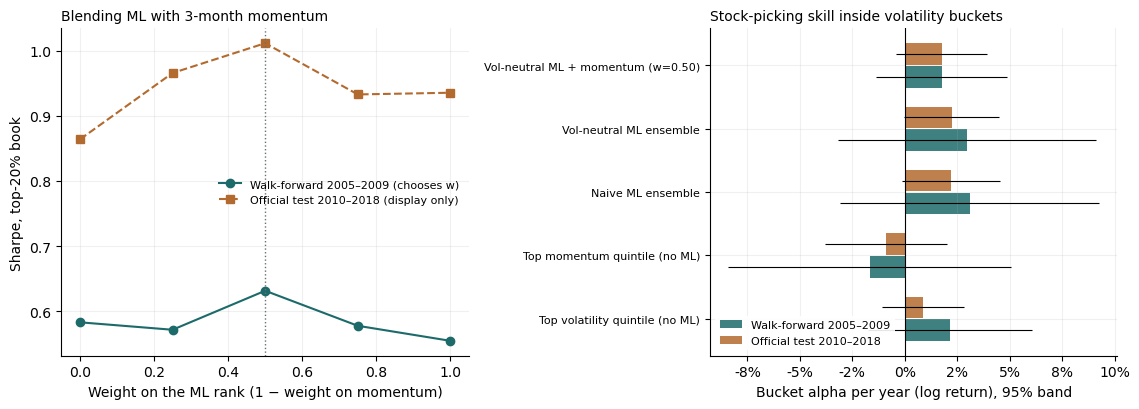

Ten inputs were fixed before any result: six cluster averages and four technical ranks. Stocks are bucketed into 5 volatility groups each month, and the label asks whether a stock beats its own bucket. Tuned test AUC runs from 0.501 to 0.507, so the models still rank stocks only slightly better than chance. Inside volatility buckets, the vol-neutral ensemble's top 20% beats its bucket by 2.2% a year on 2010–2018 (t = 1.9) and 3.0% a year on the 2005–2009 walk-forward (t = 0.9). Neither is significant on its own. The ML-plus-momentum blend uses weight 0.50 on the ML rank, chosen on 2005–2009. On 2010–2018 it has Sharpe 1.01 and max drawdown -16.8%, against 0.87 and -20.7% for equal weight. The volatility-only rule has Sharpe 0.84 and volatility 23.3%. The ML-plus-volatility blend chose weight 0.00, so it equals the volatility rule. The 2010–2018 window was already viewed, results are gross of costs, and these are 108 months on one path.


In [14]:
from research.notebook_views import vol_neutral_figure, vol_neutral_model_table, vol_neutral_note

part8_formats = {"Annual log growth": PERCENT, "CAGR": PERCENT, "Volatility": PERCENT, "Max drawdown": PERCENT,
                 "Sharpe": "{:.3f}", "Bucket alpha / yr": PERCENT, "Alpha t": "{:.2f}"}
for window, title in (("oos_2005_2009", "Walk-forward 2005–2009 (used to choose w)"),
                      ("test_2010_2018", "Official test 2010–2018")):
    print(title)
    display(vol_neutral_table(window).style.format(part8_formats, na_rep="—").hide(axis="index"))

# Per model: ranking quality with the ordinary label and the volatility-neutral label.
display(vol_neutral_model_table().style.format(precision=3).hide(axis="index"))
display(vol_neutral_figure()); plt.close("all")
print(vol_neutral_note())

**Reading it.**
- **Neutralizing volatility does not create a forecasting model.** AUC stays between about 0.49 and 0.51.
- **There may be a little stock-picking skill.** The ML ensembles beat their volatility bucket in both windows, but the 95% bands include zero.
- **The ML + momentum blend is the most useful ML result.** It is the best risk-adjusted book in this study: higher Sharpe and a shallower drawdown than equal weight, with similar volatility. Its weight was chosen on training years, and the test curve peaks at the same weight. The differences between weights are still small, so I report this as promising, not proven.
- **The ML + volatility blend is just the volatility rule.** The walk-forward picked a weight of zero, which shows how fragile it is to choose a weight on five years of data.

## 8. Risk and reward

Return alone is not enough to compare these books. The table shows growth next to volatility, Sharpe and maximum drawdown for the official test, the training window, and the full path that compounds training into test. The chart after it plots every official-test candidate by risk and return.

Window,Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Average cash
Official test,Equal weight,12.31%,13.10%,15.63%,0.868,-20.64%,0.00%
Official test,Top 10 positive-vol,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test,Top 10 + downside to cash,14.53%,15.64%,30.36%,0.590,-16.65%,62.75%
Official test,Top 10 + upside tilt,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test,Full baskets,3.93%,4.01%,8.07%,0.528,-12.37%,54.18%
Official test,Baskets + downside to cash,3.10%,3.15%,6.25%,0.527,-9.67%,64.40%
Official test,Baskets + upside tilt,3.93%,4.01%,8.07%,0.528,-12.36%,54.18%
Training window,Equal weight,7.34%,7.62%,23.19%,0.433,-49.51%,0.00%
Training window,Top 10 positive-vol,19.26%,21.24%,33.13%,0.719,-21.36%,50.50%
Training window,Top 10 + downside to cash,15.63%,16.91%,25.65%,0.720,-16.71%,61.88%


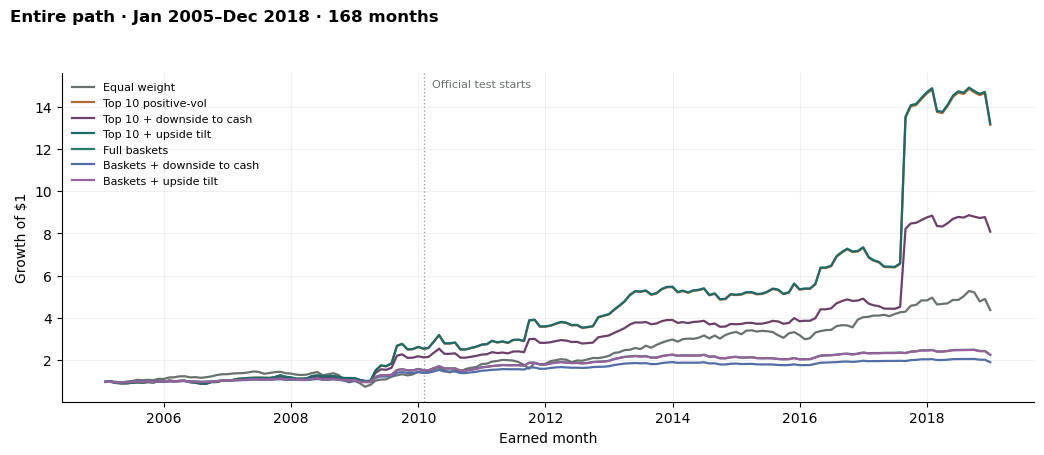

Official test is January 2010 through December 2018, the training window is January 2005 through December 2009, and the entire path is January 2005 through December 2018, compounding the training months and then the test months. On the official test, Top 10 positive-vol CAGR is 19.61% and Sharpe is 0.591, against Equal weight at 13.10% and 0.868. Equal weight's max drawdown on the entire path is -49.51%, larger than the official-test drawdown of -20.64%, because that deeper drop comes from the training window; training-window overlay rows are the saved training forecasts, while official-test rows are the one frozen fit.


In [15]:
from research.notebook_views import path_figure, risk_note

display(style_table(risk_table()))
display(path_figure()); plt.close("all")
print(risk_note())

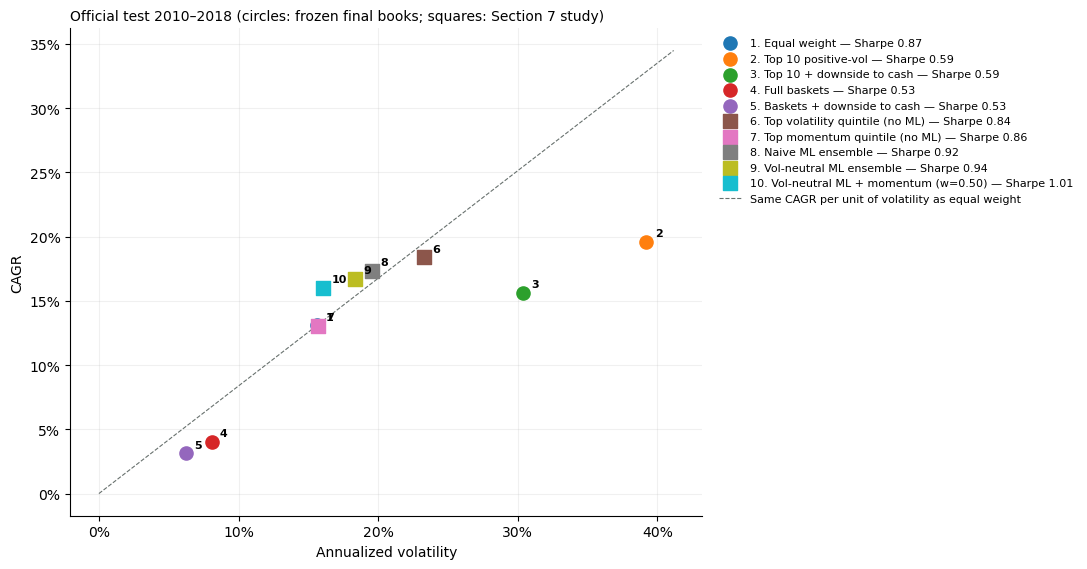

In [16]:
# Official test: risk (volatility) against reward (CAGR) for every distinct candidate.
frozen_rows = (risk_table().query("Window == 'Official test'")
               .loc[lambda d: ~d["Book"].str.contains("upside tilt")]            # identical to their base book on the test
               [["Book", "CAGR", "Volatility", "Sharpe"]].assign(Source="Frozen final books"))
study_rows = (vol_neutral_table("test_2010_2018").rename(columns={"Strategy": "Book"})
              .loc[lambda d: d["Book"].ne("Equal weight") & ~d["Book"].str.startswith("Vol-neutral ML + volatility")]
              [["Book", "CAGR", "Volatility", "Sharpe"]].assign(Source="Section 7 study"))
points = pd.concat([frozen_rows, study_rows], ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 5.8))
colors = plt.get_cmap("tab10").colors
for n, row in enumerate(points.itertuples(), start=1):
    marker = "o" if row.Source == "Frozen final books" else "s"
    ax.scatter(row.Volatility, row.CAGR, s=90, marker=marker, color=colors[(n - 1) % 10], zorder=3,
               label=f"{n}. {row.Book} — Sharpe {row.Sharpe:.2f}")
    ax.annotate(str(n), (row.Volatility, row.CAGR), fontsize=8, fontweight="bold", xytext=(6, 4), textcoords="offset points")
ew = points.set_index("Book").loc["Equal weight"]
line = np.linspace(0, points.Volatility.max() * 1.05, 50)
ax.plot(line, line * ew.CAGR / ew.Volatility, color="#68716e", lw=0.8, ls="--",
        label="Same CAGR per unit of volatility as equal weight")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Annualized volatility"); ax.set_ylabel("CAGR")
ax.set_title("Official test 2010–2018 (circles: frozen final books; squares: Section 7 study)", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0)); prepare_axes(ax)
plt.tight_layout(); plt.show()

**Reading it.** Points above the dashed line earn more return per unit of volatility than equal weight. My chosen book has the highest growth in the chart but sits *below* the line: it pays for its return with much more volatility. Its drawdown, though, is similar to equal weight's on the test and far smaller over 2005–2009, because it moves to cash in falling markets. The ML + momentum blend from Section 7 is the candidate above the line.

### 8b. What do trading costs do?

Every result so far is gross of costs. The momentum books change names and move in and out of cash every month, so costs matter more for them than for equal weight.

The cell charges 0, 10 and 25 basis points per dollar traded, using each book's saved monthly turnover. The charge counts both the sale and the purchase, and the first month pays for buying in. Moves into cash need only a sale, so the estimate is slightly conservative.

In [17]:
from research.notebook_views import cost_note, cost_table

cost_formats = {"Avg one-way turnover / month": "{:.1%}"}
for window in ("test", "training"):
    table = cost_table(window)
    cost_formats.update({c: (PERCENT if c.startswith("CAGR") else "{:.3f}") for c in table.columns if "@" in c})
    display(table.style.format(cost_formats).hide(axis="index"))
    print(cost_note(window))

Book,Avg one-way turnover / month,CAGR @ 0 bps,Sharpe @ 0 bps,CAGR @ 10 bps,Sharpe @ 10 bps,CAGR @ 25 bps,Sharpe @ 25 bps
Equal weight,2.9%,13.10%,0.868,12.99%,0.862,12.84%,0.853
Top 10 positive-vol,54.2%,19.61%,0.591,18.08%,0.557,15.80%,0.507
Top 10 + downside to cash (logistic),41.7%,15.64%,0.590,14.49%,0.556,12.79%,0.507
Full baskets,51.2%,4.01%,0.528,2.73%,0.374,0.85%,0.144


Official test 2010–2018: Top 10 positive-vol trades 54% of the portfolio each month against 3% for equal weight. At 25 bps per dollar traded its CAGR falls from 19.6% to 15.8%, and equal weight's from 13.1% to 12.8%.


Book,Avg one-way turnover / month,CAGR @ 0 bps,Sharpe @ 0 bps,CAGR @ 10 bps,Sharpe @ 10 bps,CAGR @ 25 bps,Sharpe @ 25 bps
Equal weight,3.7%,7.62%,0.433,7.48%,0.428,7.27%,0.419
Top 10 positive-vol,57.8%,21.24%,0.719,19.59%,0.678,17.16%,0.615
Top 10 + downside to cash (logistic),44.7%,16.91%,0.720,15.68%,0.679,13.85%,0.617
Full baskets,47.1%,9.59%,0.663,8.36%,0.591,6.55%,0.482


Training window 2005–2009: Top 10 positive-vol trades 58% of the portfolio each month against 4% for equal weight. At 25 bps per dollar traded its CAGR falls from 21.2% to 17.2%, and equal weight's from 7.6% to 7.3%.


**Reading it.** The chosen book trades about half its value every month, roughly 15 to 20 times equal weight's turnover. Costs take a few points of CAGR from it, but even at 25 bps it still grows faster than equal weight in both windows. On the test its Sharpe gap to equal weight widens. Full baskets, whose test growth was already low, loses almost all of it.

### 8c. Is the extra return reliable?

Higher growth over 108 months could be luck. The cell compares the chosen book with equal weight month by month, using a paired t-test on the monthly return difference. It also runs a block bootstrap, which resamples 6-month blocks 10,000 times so that short-run patterns in returns are kept, to put intervals around the extra return and the Sharpe difference.

In [18]:
from research.notebook_views import significance_note, significance_table

sig = significance_table()
display(sig.style.format({"Extra return / yr": "{:+.2%}", "t-stat": "{:.2f}", "p-value": "{:.2f}",
                          "95% CI low": "{:+.1%}", "95% CI high": "{:+.1%}", "Share of months ahead": "{:.0%}",
                          "Sharpe difference": "{:+.2f}", "Sharpe diff CI low": "{:+.2f}",
                          "Sharpe diff CI high": "{:+.2f}"}).hide(axis="index"))
print(significance_note())

Window,Months,Extra return / yr,t-stat,p-value,95% CI low,95% CI high,Share of months ahead,Sharpe difference,Sharpe diff CI low,Sharpe diff CI high
Official test 2010–2018,108,+9.59%,0.71,0.48,-10.4%,+37.6%,39%,-0.28,-0.91,+0.34
Training window 2005–2009,60,+13.78%,1.17,0.25,-6.5%,+38.1%,47%,+0.29,-0.72,+0.86
Entire path 2005–2018,168,+11.09%,1.15,0.25,-4.3%,+30.3%,42%,-0.03,-0.59,+0.45


On the official test the chosen book earns +9.6% a year more than equal weight (arithmetic, t = 0.71, p = 0.48; block-bootstrap 95% interval -10.4% to +37.6%). That is not significant at 5%. Over 2005–2018 the gap is +11.1% a year (t = 1.15, p = 0.25). Its Sharpe is lower than equal weight's on the test by 0.28, with a bootstrap interval of -0.91 to +0.34. The higher growth is real in the sample but noisy, and it is bought with volatility.


**Reading it.** The chosen book's higher average return is **not statistically significant** in any window, and every interval includes zero. It beats equal weight in fewer than half of the months, so its gains come from a smaller number of large months. That is typical of a high-volatility book that sits partly in cash. The Sharpe difference is just as uncertain. The honest summary: the growth advantage showed up in both windows, but with this much volatility, 5 to 14 years of data cannot prove it.

## 9. Final choice

**The book I would trade: Top 10 positive-vol, with no ML overlay.** Each month it forms five K-means groups from 12-month return paths, keeps at most ten high positive-volatility names per group, invests only where one-month momentum is positive, and leaves the rest in cash.

**Why this one.**
- **It has the highest growth on both windows.** Among the non-ML books, it grows fastest on the official test *and* in the 2005–2009 training window, so the choice does not rest on the test alone. The only frozen book with more test growth is gradient boosting's upside tilt, which gets there by adding volatility and has a lower Sharpe.
- **The ML overlays do not improve it.** Downside-to-cash trims return and keeps the same Sharpe, upside tilt does nothing, and tuning and feature cuts do not change that (Sections 3–5). Leaving the forecast out keeps the strategy simple and honest about where its return comes from.
- **It holds up in bad markets.** It moves to cash in falling markets, so its worst drawdown is similar to equal weight's on the test and much smaller through 2008.

**The trade-off, stated plainly.** Its volatility is about 2.5 times equal weight's, and its Sharpe ratio is lower. It trades about half the portfolio each month, so costs take a few points of growth, though it still leads at 25 bps (Section 8b). Its extra return is not statistically significant (Section 8c). An investor who cares about risk-adjusted return rather than growth should prefer **equal weight** or the **ML + momentum blend** from Section 7. That blend has the best Sharpe here, but its weight was chosen on a short, noisy window and the test period had already been viewed.

In [19]:
from research.notebook_views import choice_text

# Official-test numbers for the declared choice, read from the frozen final-book run.
print(choice_text())

The book I would trade is Top 10 positive-vol, with an official-test annual log growth of 17.9%, CAGR of 19.6%, volatility of 39.2%, a Sharpe of 0.591, and a max drawdown of -21.3%, against equal weight at annual log growth of 12.3%, CAGR of 13.1%, volatility of 15.6%, a Sharpe of 0.868, and a max drawdown of -20.6%. Its annual log growth and its CAGR are higher than equal weight and its Sharpe is lower than equal weight. For Logistic regression, Top 10 + downside to cash changes CAGR by -4.0 percentage points versus the unadjusted book, and Top 10 + upside tilt does not change the book, while the test CAGR for Full baskets is 4.0% and its Sharpe is 0.528, both lower than equal weight. The 2010–2018 score was run once, after the comparison was written down. Those official books use factory classifier settings. The final study metadata records fit_policy frozen_at_origin, fit_snapshot 2009-12-31, and n_features 10.


### Limitations

- **The test period was viewed more than once** across the project's studies. The frozen final books were scored once, after the comparison was written down. Later studies that read 2010–2018 are labeled as checks.
- **Costs and cash.** Headline numbers are gross of costs. Section 8b shows the effect of 10–25 bps. Cash is assumed to earn 0%, which slightly understates the books that hold cash.
- **One market path.** 108 test months are one sample, and several strategies were compared, so small differences are not significant.
- **The 10-feature limit.** Engineered recipes use at most ten inputs, but some combine all twenty source factors. ANOVA-10 is the cut that strictly uses ten original factors.
- **Different protocols.** The Section 7 study uses a top-20%, fully invested rule on complete-history stocks, so its rows compare cleanly with each other but only roughly with the frozen books.